# 07: GhanaTok Vocabulary Size Sweep (4,000, 8,000, 16,000, 32,000)

**Objective**: Systematically train GhanaTok (both Byte-level BPE and SentencePiece Unigram) across four vocabulary sizes (4k, 8k, 16k, 32k), evaluate each on the held-out test sets for Twi and Ewe, and empirically validate the 8,000-token design choice.

## 1. Setup & Imports

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import PreTrainedTokenizerFast

sys.path.append("..")
from src.train_ghanatok import (
    train_ghanatok,
    train_ghanatok_unigram,
    SentencePieceWrapper,
    PROJECT_ROOT,
)
from src.tokenizer_benchmark import run_benchmark

VOCAB_SIZES = [4000, 8000, 16000, 32000]

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


## 2. Load Sweep Tokenizers
We load all 8 trained models from `models/ghanatok_{bpe,unigram}_{vocab_size}/`.

In [2]:
sweep_tokenizers = {}
for vocab_size in VOCAB_SIZES:
    bpe_path = PROJECT_ROOT / "models" / f"ghanatok_bpe_{vocab_size}" / "ghanatok_tokenizer.json"
    sweep_tokenizers[f"BPE-{vocab_size}"] = PreTrainedTokenizerFast(
        tokenizer_file=str(bpe_path),
        unk_token="<unk>", pad_token="<pad>", bos_token="<s>", eos_token="</s>",
    )

    unigram_path = PROJECT_ROOT / "models" / f"ghanatok_unigram_{vocab_size}" / "ghanatok_unigram.model"
    sweep_tokenizers[f"Unigram-{vocab_size}"] = SentencePieceWrapper(str(unigram_path))

print("Loaded tokenizers:", list(sweep_tokenizers.keys()))

Loaded tokenizers: ['BPE-4000', 'Unigram-4000', 'BPE-8000', 'Unigram-8000', 'BPE-16000', 'Unigram-16000', 'BPE-32000', 'Unigram-32000']


## 3. Load Summary Results & Display Table
We load the aggregated sweep results generated from the held-out test sets (`data/processed/twi/test.txt` and `data/processed/ewe/test.txt`).

In [3]:
summary_csv = PROJECT_ROOT / "reports" / "tables" / "vocab_size_sweep_summary.csv"
sweep_summary = pd.read_csv(summary_csv)
display(sweep_summary)

,language,tokenizer,mean_fertility,mean_tokens_per_char,mean_pct_words_split,n_sentences,algorithm,vocab_size
0,ewe,BPE-4000,1.846,0.359,55.452,347,BPE,4000
1,ewe,BPE-8000,1.750,0.341,51.253,347,BPE,8000
2,ewe,BPE-16000,1.712,0.334,49.735,347,BPE,16000
3,ewe,BPE-32000,1.712,0.334,49.735,347,BPE,32000
4,ewe,Unigram-4000,1.494,0.291,30.003,347,Unigram,4000
5,ewe,Unigram-8000,1.349,0.263,22.825,347,Unigram,8000
6,ewe,Unigram-16000,1.296,0.253,21.991,347,Unigram,16000
7,ewe,Unigram-32000,1.296,0.253,21.991,347,Unigram,32000
8,twi,BPE-4000,1.777,0.351,54.616,608,BPE,4000
9,twi,BPE-8000,1.656,0.327,48.819,608,BPE,8000


## 4. Step-wise Relative Improvements
We calculate the relative percentage fertility reduction between consecutive vocabulary sizes (4k -> 8k, 8k -> 16k, 16k -> 32k).

In [4]:
for language in ["twi", "ewe"]:
    for algorithm in ["BPE", "Unigram"]:
        subset = sweep_summary[
            (sweep_summary["language"] == language) & (sweep_summary["algorithm"] == algorithm)
        ].sort_values("vocab_size")
        fert = subset.set_index("vocab_size")["mean_fertility"]
        print(f"\n{language.upper()} {algorithm}:")
        sizes = list(fert.index)
        for i in range(1, len(sizes)):
            prev_size, curr_size = sizes[i-1], sizes[i]
            prev_fert, curr_fert = fert[prev_size], fert[curr_size]
            pct_change = (prev_fert - curr_fert) / prev_fert * 100
            print(f"  {prev_size:>5} -> {curr_size:>5}: fertility {prev_fert:.3f} -> {curr_fert:.3f} ({pct_change:+.2f}%)")


TWI BPE:
   4000 ->  8000: fertility 1.777 -> 1.656 (+6.81%)
   8000 -> 16000: fertility 1.656 -> 1.585 (+4.29%)
  16000 -> 32000: fertility 1.585 -> 1.585 (+0.00%)

TWI Unigram:
   4000 ->  8000: fertility 1.354 -> 1.251 (+7.61%)
   8000 -> 16000: fertility 1.251 -> 1.212 (+3.12%)
  16000 -> 32000: fertility 1.212 -> 1.212 (+0.00%)

EWE BPE:
   4000 ->  8000: fertility 1.846 -> 1.750 (+5.20%)
   8000 -> 16000: fertility 1.750 -> 1.712 (+2.17%)
  16000 -> 32000: fertility 1.712 -> 1.712 (+0.00%)

EWE Unigram:
   4000 ->  8000: fertility 1.494 -> 1.349 (+9.71%)
   8000 -> 16000: fertility 1.349 -> 1.296 (+3.93%)
  16000 -> 32000: fertility 1.296 -> 1.296 (+0.00%)


## 5. Visualizing Fertility vs Vocabulary Size

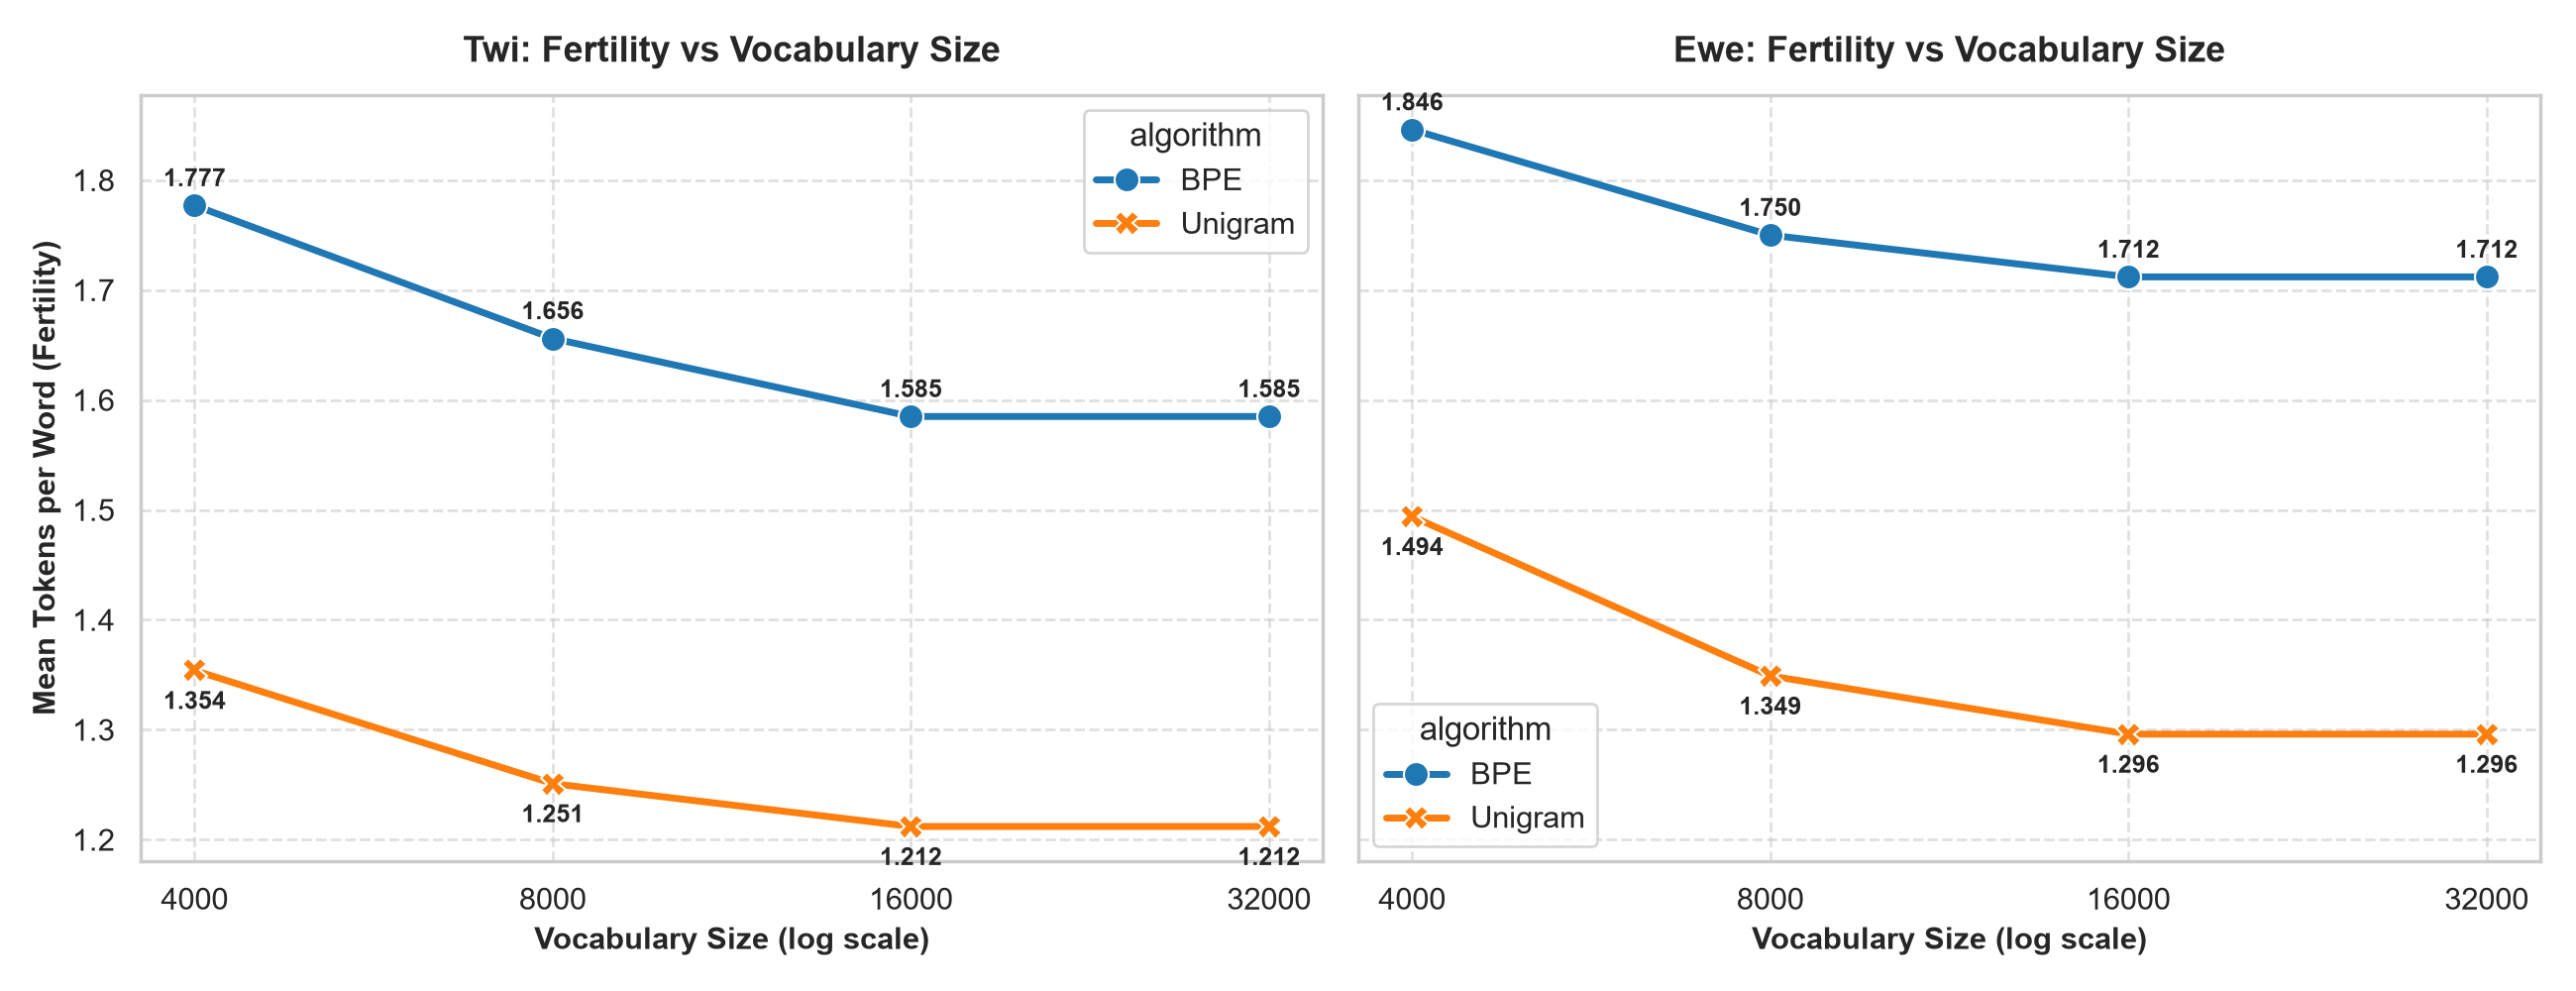

In [5]:
from IPython.display import Image
figure_path = PROJECT_ROOT / "reports" / "figures" / "vocab_size_sweep_fertility.png"
Image(filename=str(figure_path))